
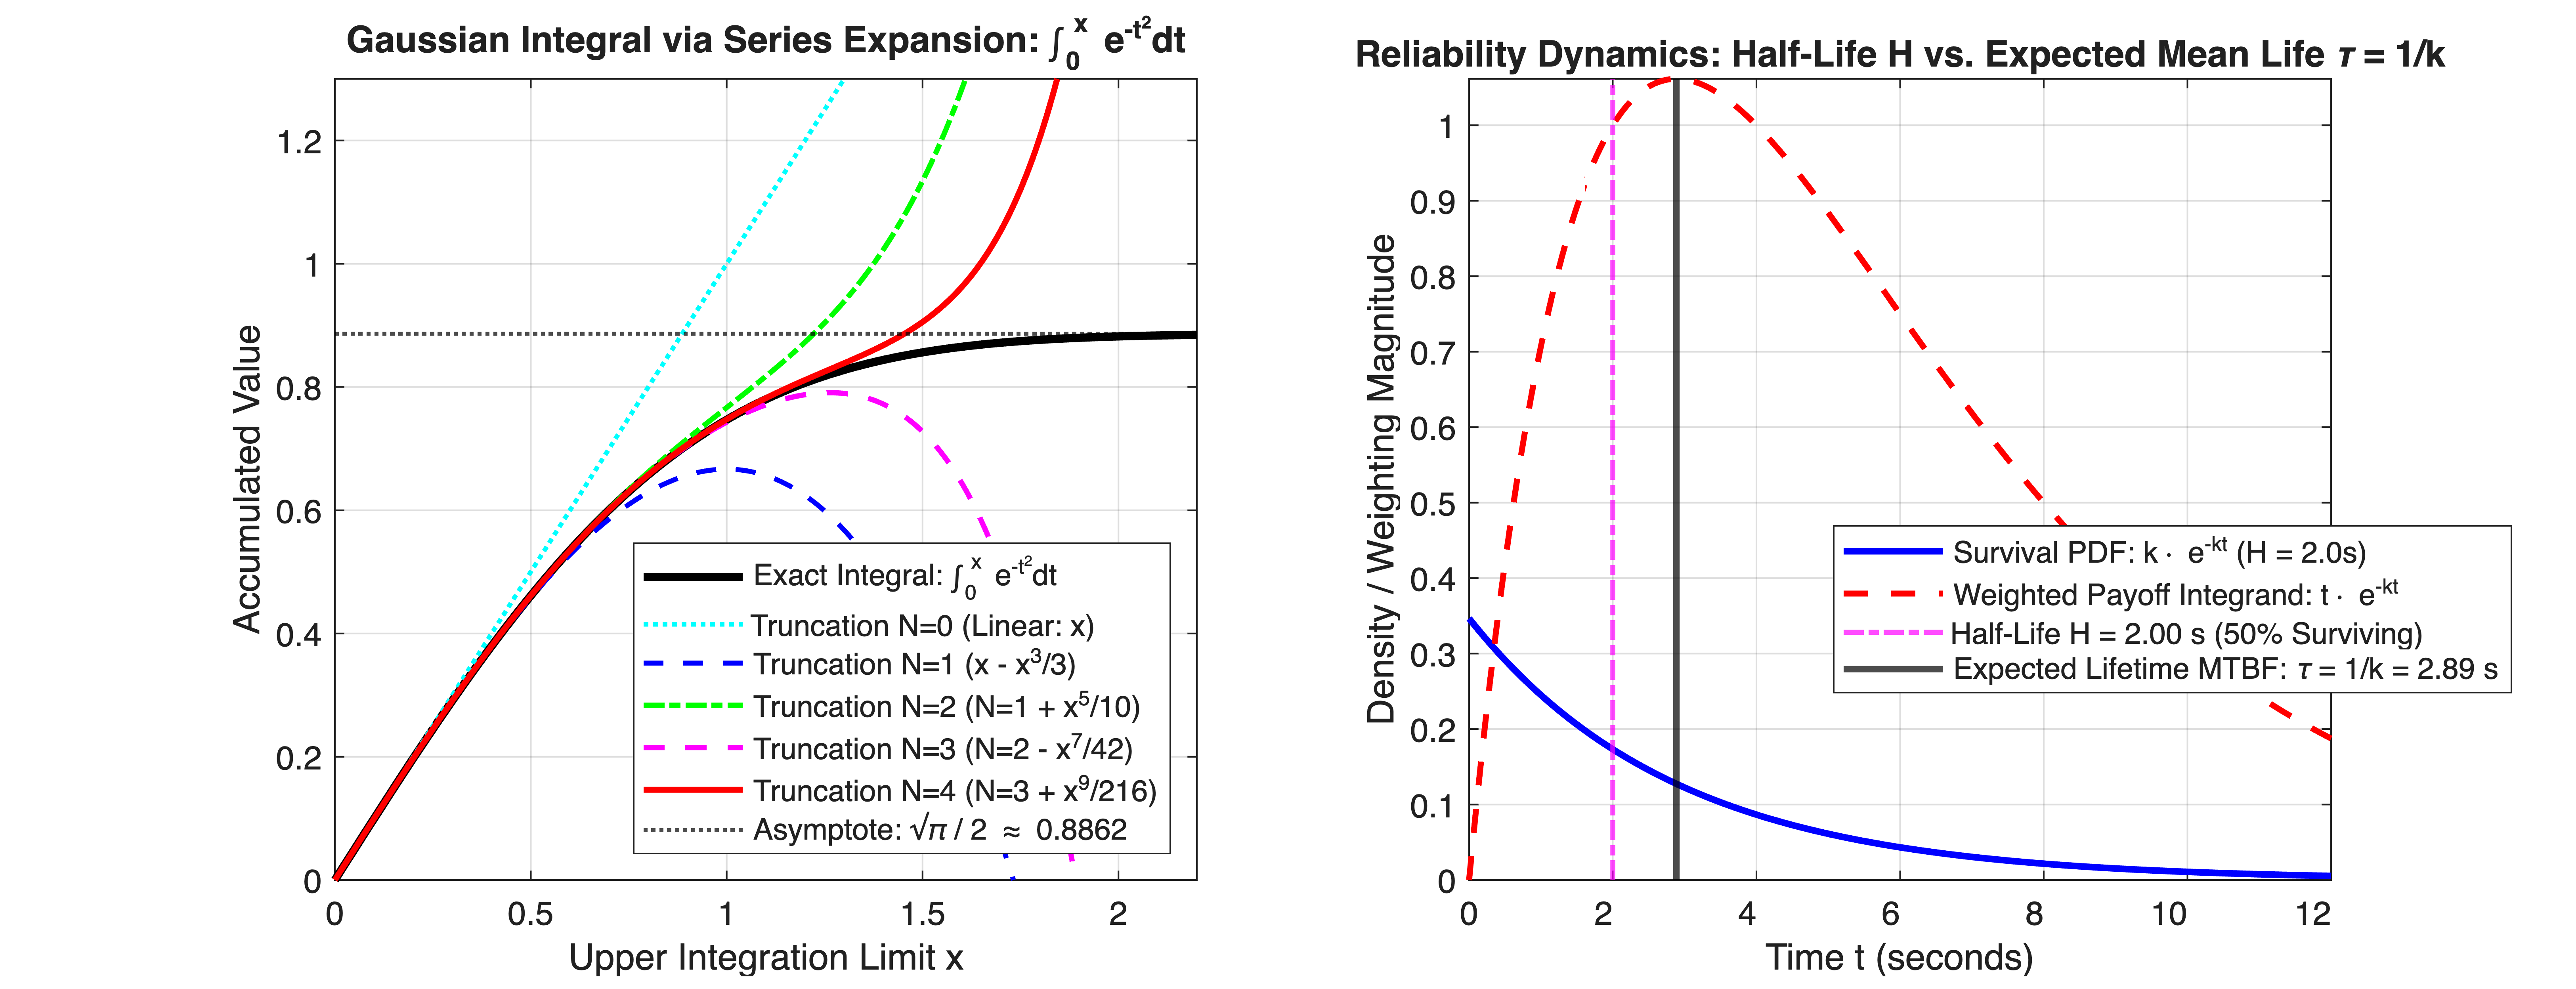

In [1]:
%% MIT 18.01 Lecture 38: Series Integration & Reliability Expectation Simulation
% Mathematical Tool Application: Used for embedded evaluation of Gaussian error
% functions in Kalman filters, reliability lifecycle modeling (MTBF / functional safety),
% and continuous discounted-horizon annuity integration in predictive control.


clear; clc; close all;


%% Part 1: Gaussian Error Function via Term-by-Term Series Integration
% True target: F(x) = \int_0^x e^{-t^2} dt = (sqrt(pi)/2) * erf(x)
x_span = linspace(0.0, 2.2, 300);
F_exact = (sqrt(pi) / 2.0) * erf(x_span);


% Successive Maclaurin Partial Sums derived in Lecture 38:
% S_N(x) = \sum_{n=0}^N [ (-1)^n * x^(2n+1) ] / [ n! * (2n+1) ]
S0 = x_span;                                                     % Order 1: x
S1 = S0 - (x_span.^3) / 3.0;                                     % Order 3: x - x^3/3
S2 = S1 + (x_span.^5) / (2.0 * 5.0);                             % Order 5: S1 + x^5/10
S3 = S2 - (x_span.^7) / (6.0 * 7.0);                             % Order 7: S2 - x^7/42
S4 = S3 + (x_span.^9) / (24.0 * 9.0);                            % Order 9: S3 + x^9/216


figure('Color', 'w', 'Position', [100, 100, 1250, 480]);


subplot(1, 2, 1);
plot(x_span, F_exact, 'k-', 'LineWidth', 2.5, 'DisplayName', 'Exact Integral: \int_0^x e^{-t^2}dt'); hold on;
plot(x_span, S0, 'c:',  'LineWidth', 1.4, 'DisplayName', 'Truncation N=0 (Linear: x)');
plot(x_span, S1, 'b--', 'LineWidth', 1.5, 'DisplayName', 'Truncation N=1 (x - x^3/3)');
plot(x_span, S2, 'g-.', 'LineWidth', 1.6, 'DisplayName', 'Truncation N=2 (N=1 + x^5/10)');
plot(x_span, S3, 'm--', 'LineWidth', 1.6, 'DisplayName', 'Truncation N=3 (N=2 - x^7/42)');
plot(x_span, S4, 'r-',  'LineWidth', 1.8, 'DisplayName', 'Truncation N=4 (N=3 + x^9/216)');


yline(sqrt(pi)/2.0, 'k:', 'LineWidth', 1.2, 'DisplayName', 'Asymptote: \surd\pi / 2 \approx 0.8862');


grid on;
xlim([0, 2.2]); ylim([0, 1.3]);
xlabel('Upper Integration Limit x');
ylabel('Accumulated Value');
title('Gaussian Integral via Series Expansion: \int_0^x e^{-t^2}dt');
legend('Location', 'southeast');


%% Part 2: Reliability Expected Lifetime (MTBF) & Weighted Average Integration
subplot(1, 2, 2);


% Physical parameters from Lecture 38: Half-life H = 2.0 s
% Decay constant k = ln(2) / H => Expected Life MTBF = 1/k = H / ln(2)
H_halflife = 2.0;
k_decay = log(2.0) / H_halflife;
mean_life_tau = 1.0 / k_decay; % approx 2.8854 s


t_domain = linspace(0, 12.0, 400);
w_density = k_decay * exp(-k_decay * t_domain); % Normalized PDF
integrand_numerator = t_domain .* exp(-k_decay * t_domain);


% Plot probability density and expectation centroid
plot(t_domain, w_density, 'b-', 'LineWidth', 2.0, ...
    'DisplayName', sprintf('Survival PDF: k\\cdot e^{-kt} (H = %.1fs)', H_halflife)); hold on;
plot(t_domain, integrand_numerator, 'r--', 'LineWidth', 1.8, ...
    'DisplayName', 'Weighted Payoff Integrand: t\cdot e^{-kt}');


% Mark Half-Life and Mean Expected Lifetime (MTBF)
xline(H_halflife, 'm-.', 'LineWidth', 1.5, ...
    'DisplayName', sprintf('Half-Life H = %.2f s (50%% Surviving)', H_halflife));
xline(mean_life_tau, 'k-', 'LineWidth', 2.0, ...
    'DisplayName', sprintf('Expected Lifetime MTBF: \\tau = 1/k = %.2f s', mean_life_tau));


grid on;
xlim([0, 12.0]); ylim([0, max(w_density) * 1.15]);
xlabel('Time t (seconds)');
ylabel('Density / Weighting Magnitude');
title('Reliability Dynamics: Half-Life H vs. Expected Mean Life \tau = 1/k');
legend('Location', 'northeast');

In [2]:


%% Numerical Validation of Pi/2 Series (Lecture 38 Page 1-2)
% pi/2 = 1 + (1/2)*(1/3) + (1*3)/(2*4)*(1/5) + (1*3*5)/(2*4*6)*(1/7) + ...
exact_half_pi = pi / 2.0;
num_terms = 200;
pi_over_2_series = 1.0;
coeff_prod = 1.0;


for n = 1:num_terms
    coeff_prod = coeff_prod * ( (2*n - 1) / (2*n) );
    pi_over_2_series = pi_over_2_series + coeff_prod * (1.0 / (2*n + 1));
end


fprintf('\n=== Lecture 38 Series Verification: \\pi/2 via Binomial Expansion ===\n');

=== Lecture 38 Series Verification: \pi/2 via Binomial Expansion ===

In [3]:
fprintf('Calculated Series (N = %d terms): %.10f\n', num_terms, pi_over_2_series);

Calculated Series (N = 200 terms): 1.5309932418

In [4]:
fprintf('Exact \\pi / 2 Theoretical Value   : %.10f\n', exact_half_pi);

Exact \pi / 2 Theoretical Value   : 1.5707963268

In [5]:
fprintf('Truncation Discrepancy Error      : %.2e\n', abs(exact_half_pi - pi_over_2_series));

Truncation Discrepancy Error      : 3.98e-02